In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
FROZEN_EPOCHS = 8
FINE_TUNE_EPOCHS = 5

tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
BASE_DIR = (
    '/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/'
    'New Plant Diseases Dataset(Augmented)/'
    'New Plant Diseases Dataset(Augmented)'
)
TRAIN_DIR = os.path.join(BASE_DIR, 'train')
VALID_DIR = os.path.join(BASE_DIR, 'valid')

print('Training folder:', TRAIN_DIR)
print('Validation folder:', VALID_DIR)
assert os.path.exists(TRAIN_DIR), 'Training directory was not found.'
assert os.path.exists(VALID_DIR), 'Validation directory was not found.'

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, labels='inferred', label_mode='int',
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    shuffle=True, seed=SEED
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    VALID_DIR, labels='inferred', label_mode='int',
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)
assert class_names == valid_ds.class_names, 'Training and validation class names differ.'
print(f'Number of classes: {num_classes}')
print(class_names[:10])

Training folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train
Validation folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid
Found 70295 files belonging to 38 classes.


I0000 00:00:1783939255.608477      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1783939255.611721      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 17572 files belonging to 38 classes.
Number of classes: 38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight']


In [4]:
AUTOTUNE = tf.data.AUTOTUNE
train_data = train_ds.prefetch(AUTOTUNE)
valid_data = valid_ds.prefetch(AUTOTUNE)

In [5]:
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name='data_augmentation')

base_model = keras.applications.ResNet50(
    include_top=False,
    weights='imagenet',
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_model.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='leaf_image')
x = data_augmentation(inputs)
x = keras.applications.resnet50.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name='global_average_pooling')(x)
x = layers.BatchNormalization(name='classifier_batch_norm')(x)
x = layers.Dense(
    256, activation='relu', kernel_regularizer=regularizers.l2(1e-4),
    name='dense_256'
)(x)
x = layers.Dropout(0.30, name='dropout')(x)
outputs = layers.Dense(num_classes, activation='softmax', name='disease_prediction')(x)

model = keras.Model(inputs, outputs, name='plant_disease_resnet50_frozen')
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)
model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "plant_disease_resnet50_frozen"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ leaf_image          │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ leaf_image[0][0]  │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ data_augmentatio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ data_augmentatio… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_batch_n… │ (None, 2048)      │      8,192 │ global_average_p… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_256 (Dense)   │ (None, 256)       │    524,544 │ classifier_batch… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense_256[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ disease_prediction  │ (None, 38)        │      9,766 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 24,130,214 (92.05 MB)

 Trainable params: 538,406 (2.05 MB)

 Non-trainable params: 23,591,808 (90.00 MB)

In [6]:
FROZEN_BEST_PATH = '/kaggle/working/resnet50_frozen_best.keras'
FROZEN_LAST_PATH = '/kaggle/working/resnet50_frozen_last.keras'
CLASS_NAMES_PATH = '/kaggle/working/class_names.json'

with open(CLASS_NAMES_PATH, 'w') as file:
    json.dump(class_names, file, indent=2)

frozen_callbacks = [
    ModelCheckpoint(FROZEN_BEST_PATH, monitor='val_accuracy', mode='max', save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_accuracy', mode='max', patience=4, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-7, verbose=1),
    CSVLogger('/kaggle/working/resnet50_frozen_log.csv')
]

history_frozen = model.fit(
    train_data,
    validation_data=valid_data,
    epochs=FROZEN_EPOCHS,
    callbacks=frozen_callbacks
)
model.save(FROZEN_LAST_PATH)

Epoch 1/8
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.8394 - loss: 0.6306
Epoch 1: val_accuracy improved from None to 0.94474, saving model to /kaggle/working/resnet50_frozen_best.keras

Epoch 1: finished saving model to /kaggle/working/resnet50_frozen_best.keras
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 374s 165ms/step - accuracy: 0.9035 - loss: 0.3998 - val_accuracy: 0.9447 - val_loss: 0.2920 - learning_rate: 0.0010
Epoch 2/8
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.9452 - loss: 0.2867
Epoch 2: val_accuracy improved from 0.94474 to 0.95988, saving model to /kaggle/working/resnet50_frozen_best.keras

Epoch 2: finished saving model to /kaggle/working/resnet50_frozen_best.keras
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 368s 167ms/step - accuracy: 0.9472 - loss: 0.2907 - val_accuracy: 0.9599 - val_loss: 0.2811 - learning_rate: 0.0010
Epoch 3/8
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.9546 - loss: 0.2892
Epoch 3: val_accuracy improved from 0.95988 to 0.96221, 

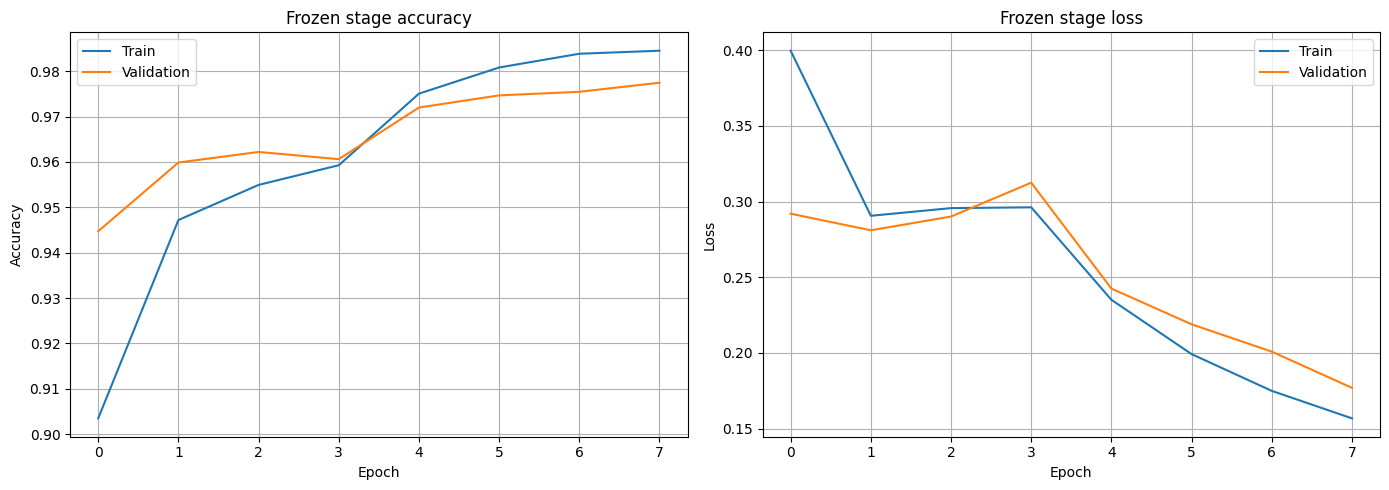

In [7]:
history_df = pd.DataFrame(history_frozen.history)
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(history_df['accuracy'], label='Train')
plt.plot(history_df['val_accuracy'], label='Validation')
plt.title('Frozen stage accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.grid()
plt.subplot(1, 2, 2)
plt.plot(history_df['loss'], label='Train')
plt.plot(history_df['val_loss'], label='Validation')
plt.title('Frozen stage loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid()
plt.tight_layout(); plt.show()

In [8]:
fine_tune_model = keras.models.load_model(FROZEN_BEST_PATH)
base_model = fine_tune_model.get_layer('resnet50')
base_model.trainable = True

# Keep most convolutional layers frozen
for layer in base_model.layers[:-30]:
    layer.trainable = False

# BatchNormalization layers should remain fixed when fine-tuning a small dataset
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

fine_tune_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

FINE_TUNED_PATH = '/kaggle/working/resnet50_finetuned_best.keras'
fine_tune_callbacks = [
    ModelCheckpoint(FINE_TUNED_PATH, monitor='val_accuracy', mode='max', save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_accuracy', mode='max', patience=3, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-7, verbose=1),
    CSVLogger('/kaggle/working/resnet50_finetuned_log.csv')
]

history_finetuned = fine_tune_model.fit(
    train_data,
    validation_data=valid_data,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=fine_tune_callbacks
)


Epoch 1/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.9872 - loss: 0.1417
Epoch 1: val_accuracy improved from None to 0.98105, saving model to /kaggle/working/resnet50_finetuned_best.keras

Epoch 1: finished saving model to /kaggle/working/resnet50_finetuned_best.keras
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 470s 209ms/step - accuracy: 0.9883 - loss: 0.1378 - val_accuracy: 0.9810 - val_loss: 0.1658 - learning_rate: 1.0000e-05
Epoch 2/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9911 - loss: 0.1290
Epoch 2: val_accuracy improved from 0.98105 to 0.98532, saving model to /kaggle/working/resnet50_finetuned_best.keras

Epoch 2: finished saving model to /kaggle/working/resnet50_finetuned_best.keras
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 459s 209ms/step - accuracy: 0.9916 - loss: 0.1280 - val_accuracy: 0.9853 - val_loss: 0.1547 - learning_rate: 1.0000e-05
Epoch 3/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9911 - loss: 0.1265
Epoch 3: val_accuracy improved from 

In [9]:
final_model = keras.models.load_model(FINE_TUNED_PATH)
validation_loss, validation_accuracy = final_model.evaluate(valid_data, verbose=1)
print(f'Final validation loss: {validation_loss:.4f}')
print(f'Final validation accuracy: {validation_accuracy:.2%}')

y_true = np.concatenate([labels.numpy() for _, labels in valid_data])
probabilities = final_model.predict(valid_data, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

print(classification_report(
    y_true, y_pred, labels=np.arange(num_classes),
    target_names=class_names, zero_division=0
))

550/550 ━━━━━━━━━━━━━━━━━━━━ 75s 130ms/step - accuracy: 0.9878 - loss: 0.1393
Final validation loss: 0.1393
Final validation accuracy: 98.78%
550/550 ━━━━━━━━━━━━━━━━━━━━ 74s 132ms/step
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      1.00      1.00       504
                                 Apple___Black_rot       1.00      1.00      1.00       497
                          Apple___Cedar_apple_rust       1.00      1.00      1.00       440
                                   Apple___healthy       1.00      1.00      1.00       502
                               Blueberry___healthy       1.00      1.00      1.00       454
          Cherry_(including_sour)___Powdery_mildew       1.00      1.00      1.00       421
                 Cherry_(including_sour)___healthy       1.00      1.00      1.00       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.95      0.99      

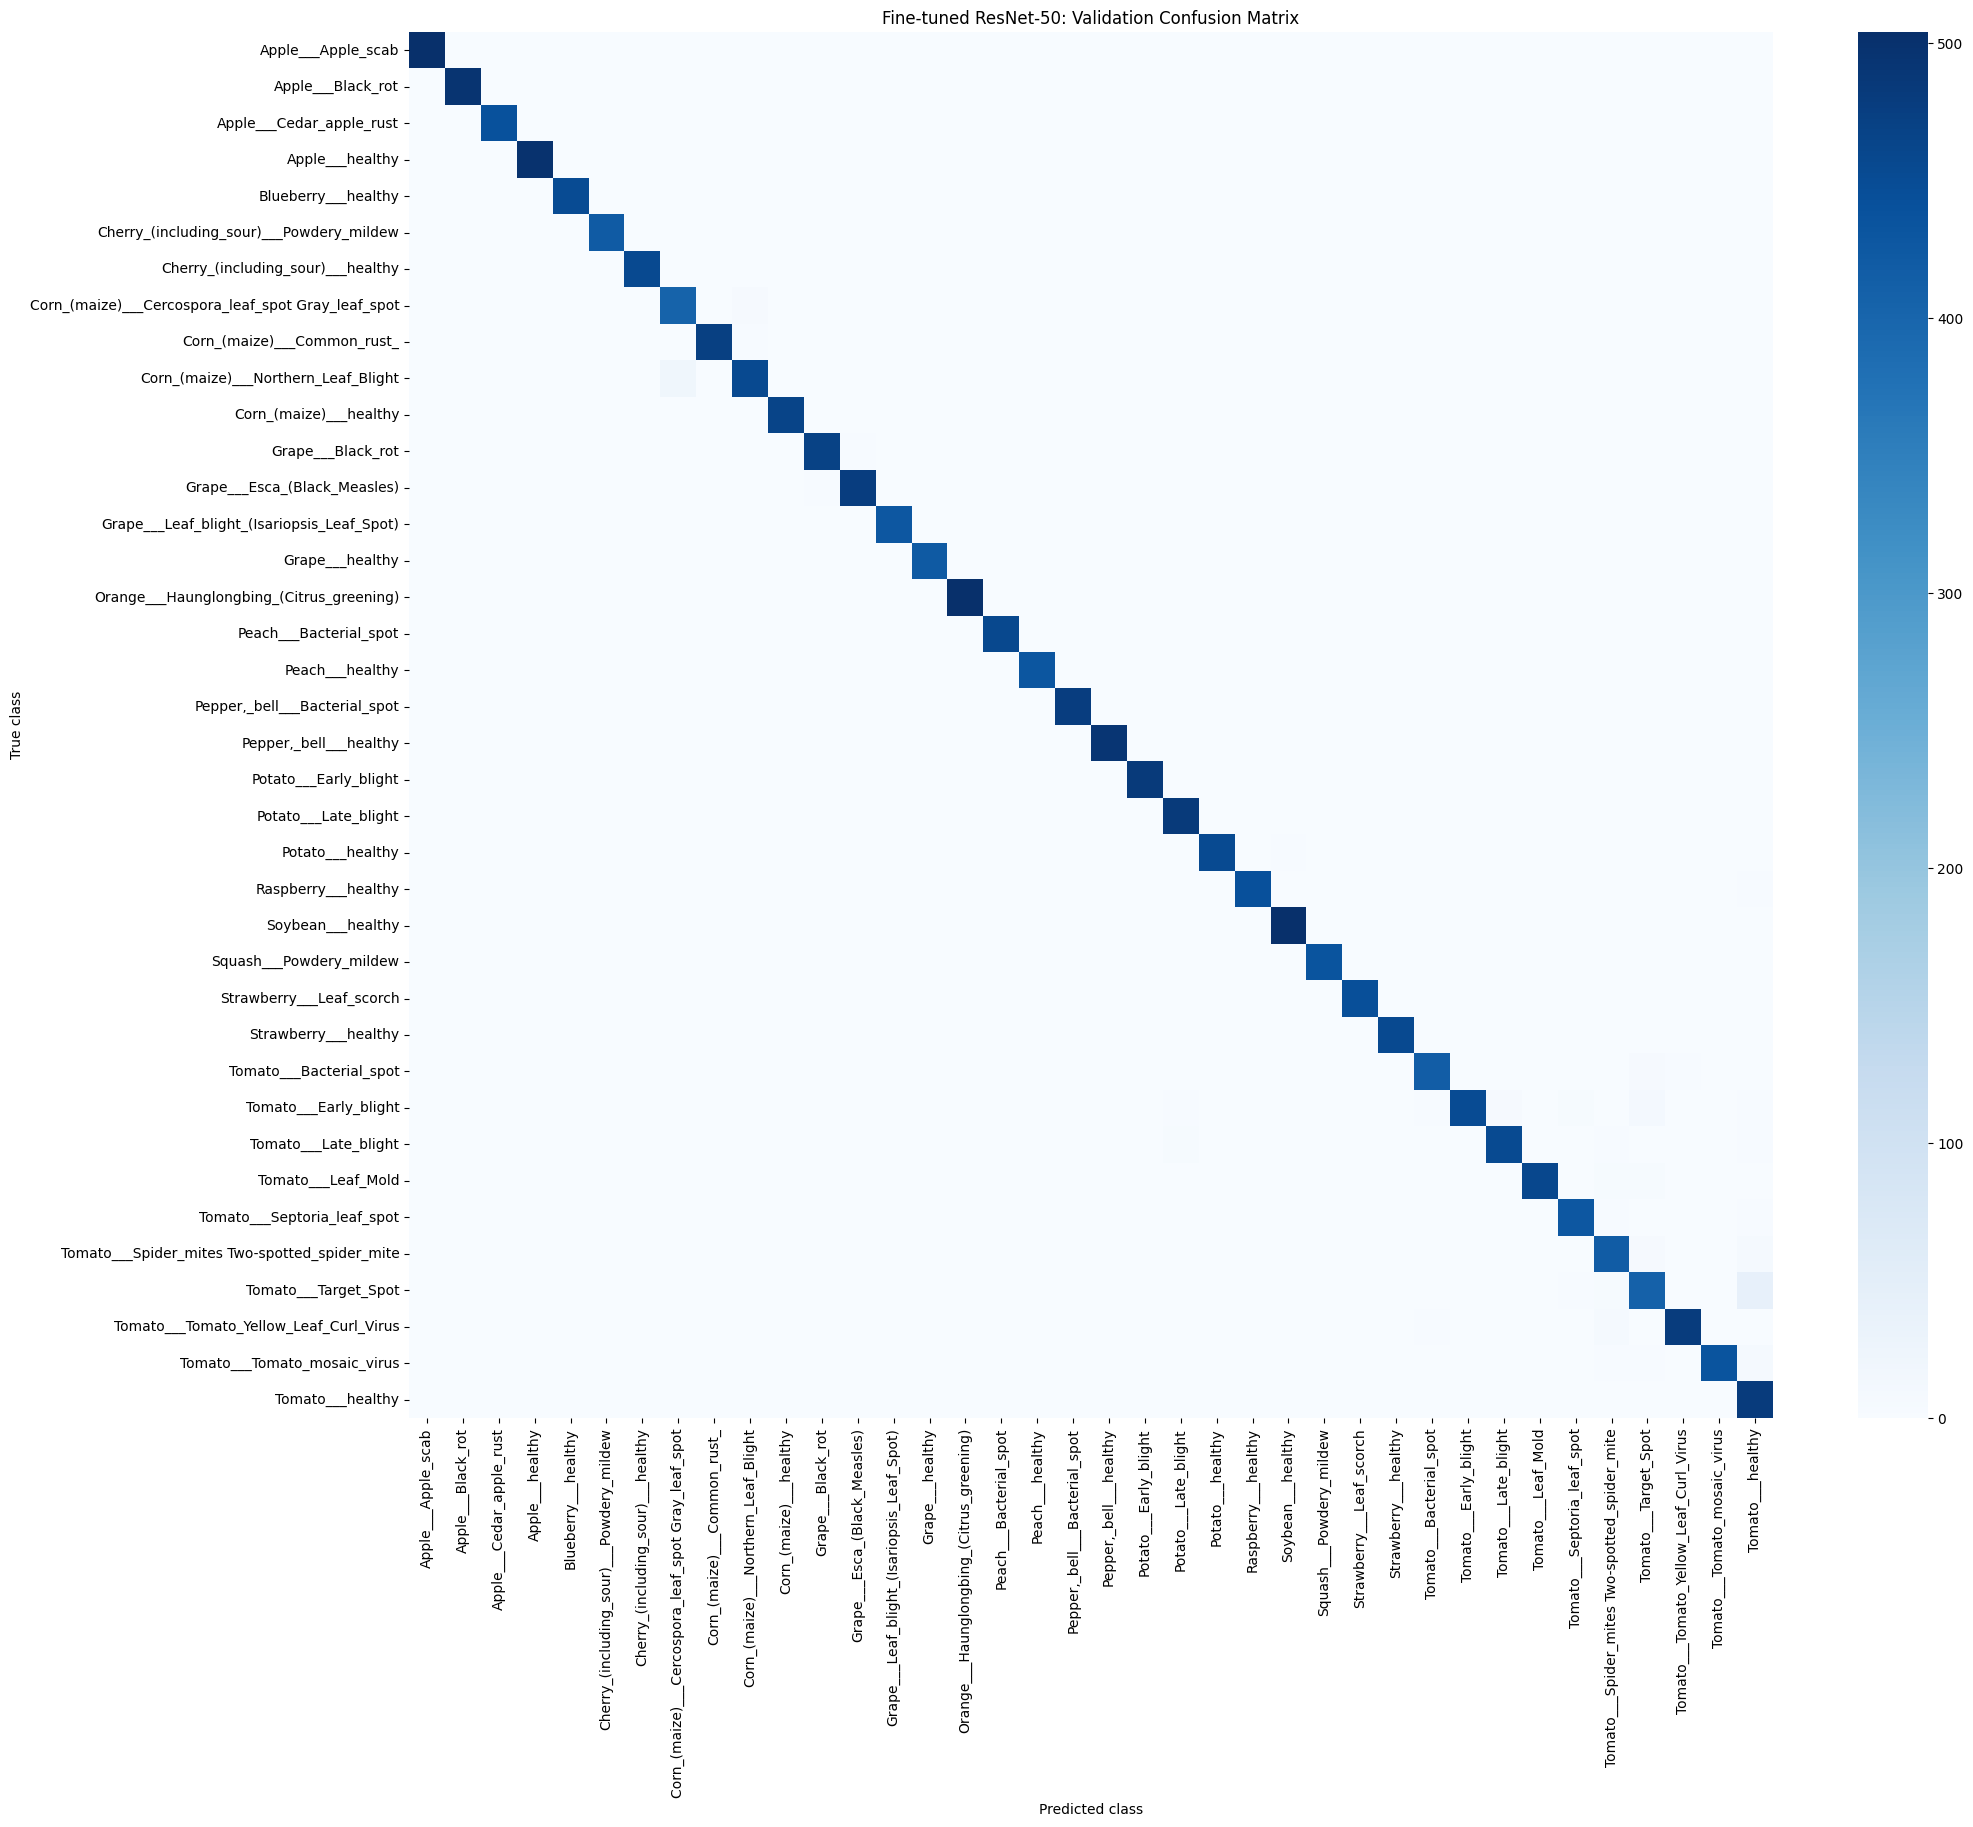

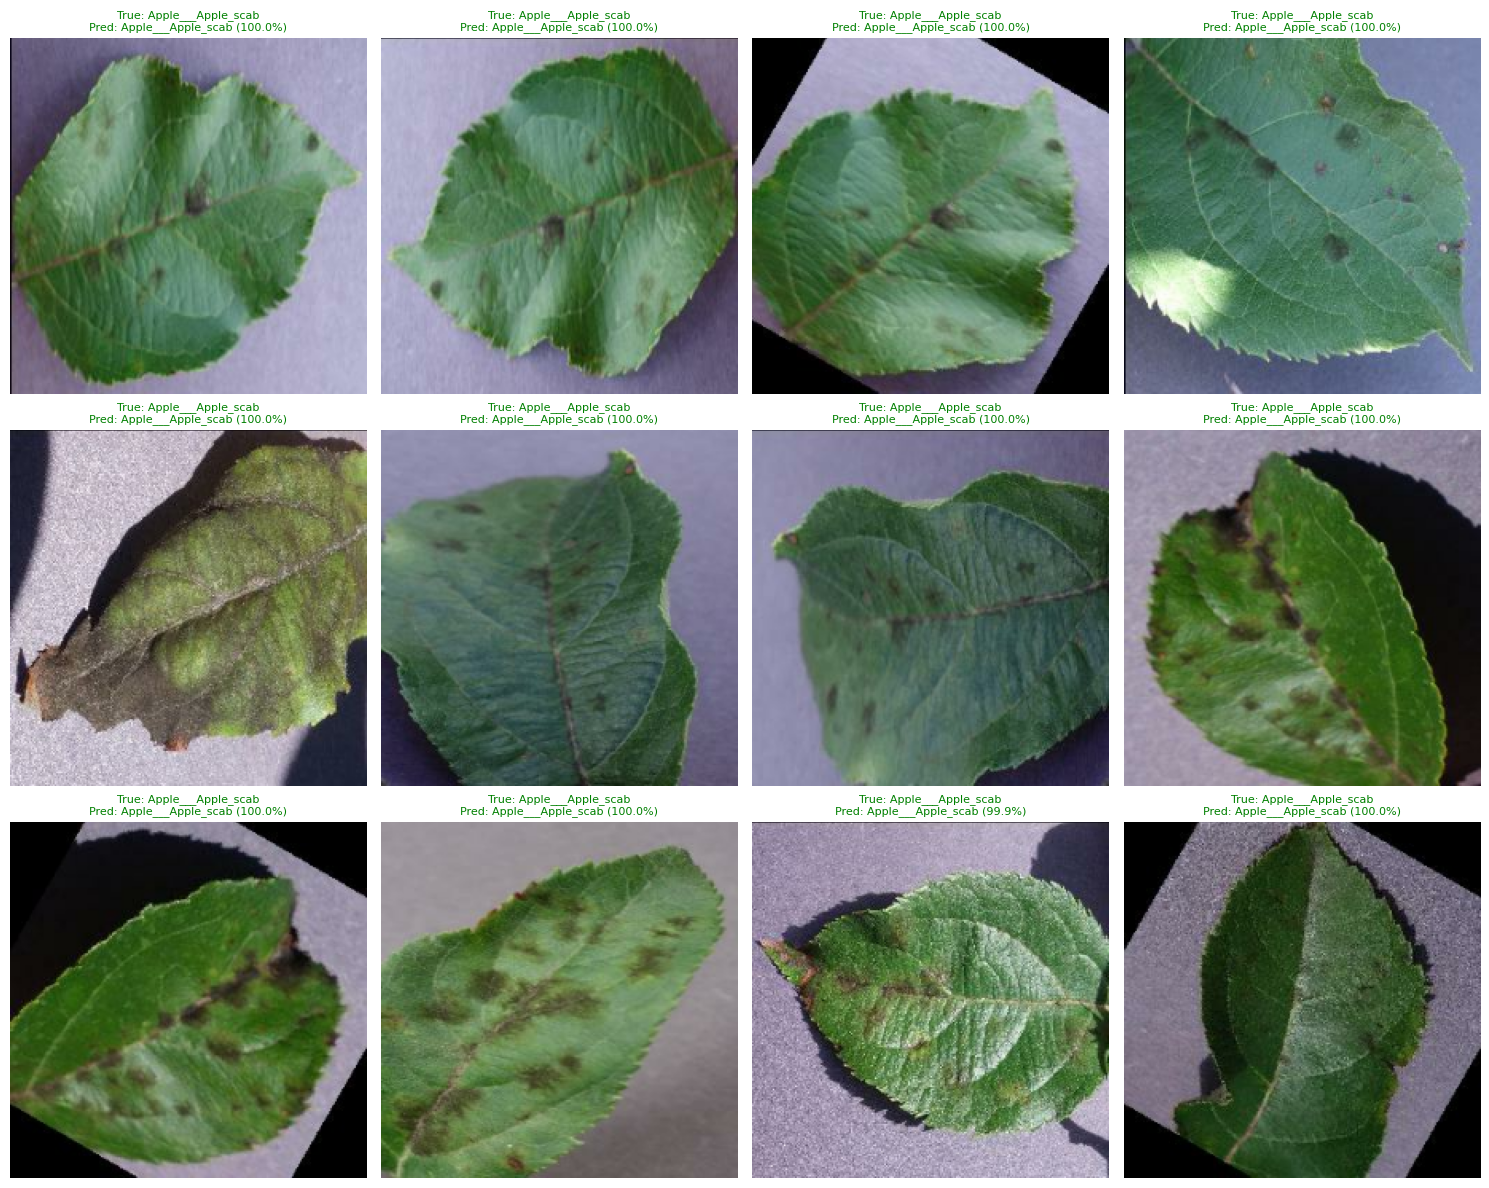

In [10]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(22, 18))
sns.heatmap(cm, cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Fine-tuned ResNet-50: Validation Confusion Matrix')
plt.xlabel('Predicted class'); plt.ylabel('True class')
plt.show()

images, labels = next(iter(valid_data))
batch_probabilities = final_model.predict(images, verbose=0)
batch_predictions = np.argmax(batch_probabilities, axis=1)

plt.figure(figsize=(15, 12))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i].numpy().astype('uint8'))
    true_name = class_names[labels[i]]
    predicted_name = class_names[batch_predictions[i]]
    confidence = batch_probabilities[i, batch_predictions[i]] * 100
    color = 'green' if labels[i] == batch_predictions[i] else 'red'
    plt.title(f'True: {true_name}\nPred: {predicted_name} ({confidence:.1f}%)', color=color, fontsize=8)
    plt.axis('off')
plt.tight_layout(); plt.show()

In [11]:
MODEL_NAME = "ResNet50"
MODEL_PATH = "/kaggle/working/resnet50_finetuned_best.keras"
final_model = keras.models.load_model(MODEL_PATH)
val_loss, val_accuracy = final_model.evaluate(valid_data, verbose=0)

In [13]:
import time
sample_images, _ = next(iter(valid_data))

start_time = time.time()
_ = final_model.predict(sample_images, verbose=0)
inference_time = time.time() - start_time

metrics = {
    "model_name": MODEL_NAME,
    "validation_accuracy": float(val_accuracy),
    "validation_loss": float(val_loss),
    "total_parameters": int(final_model.count_params()),
    "model_size_mb": round(os.path.getsize(MODEL_PATH) / (1024 * 1024), 2),
    "batch_size": BATCH_SIZE,
    "batch_inference_seconds": round(inference_time, 4),
    "seconds_per_image": round(inference_time / len(sample_images), 5)
}

In [14]:
print(json.dumps(metrics, indent=2))

with open(f"/kaggle/working/{MODEL_NAME}_metrics.json", "w") as file:
    json.dump(metrics, file, indent=2)

{
  "model_name": "ResNet50",
  "validation_accuracy": 0.9878215193748474,
  "validation_loss": 0.13927188515663147,
  "total_parameters": 24130214,
  "model_size_mb": 206.9,
  "batch_size": 32,
  "batch_inference_seconds": 1.8697,
  "seconds_per_image": 0.05843
}
